# Big Data Bowl 2027 — Does Combine Movement Predict Rookie Injury?

**Question:** for the 2023–2025 draft classes, does how a player *moves* in Combine drills (from Combine tracking) say anything about whether he is injured as a rookie, beyond what his timed Combine results already say?

**Why this route:** every player in the dataset is a 2023–2025 draftee with Combine tracking, and the weekly injury report lists every rostered player, so this covers all 510 players (about 21% injured as rookies) instead of the 15–30 injured starters in the earlier game-tracking tests. It goes straight from Combine to injury, the question a draft room actually asks.

**Guardrail (explore, then confirm):**
- Sections 1–3 use only the **2023 and 2024 classes** (explore).
- Section 4 is where the confirmation tests get written down, and they are copied into the findings doc *before* Section 5 runs.
- Section 5 tests them once on the **2025 class**. It is locked until `CONFIRM_UNLOCKED = True`.

**Sections:** 0 setup · 1 rookie-injury outcome · 2 Combine features (timed and tracked) · 3 exploration · 4 confirmation tests (pre-registration) · 5 confirmation on the 2025 class.

## 0. Setup

In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import RepeatedStratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)
sns.set_theme(style="whitegrid")

DATA, EXT = Path("../data"), Path("external")
OUT_DIR = Path("outputs/rookie_injury")
USE_SYNTHETIC = not (DATA / "players.csv").exists()
OUT_DIR.mkdir(parents=True, exist_ok=True)

EXPLORE_CLASSES = [2023, 2024]
CONFIRM_CLASS = 2025
CONFIRM_UNLOCKED = True     # set True only after Section 4's tests are copied into the findings doc

SEASONS = [2023, 2024, 2025]
IR_MIN_GAMES = 3             # an absence run this long, starting right after an injury listing, counts as missed games
EXCLUDE_INJURY = "concussion|head|illness|personal|rest|not injury|non-football"
FAMILY = {"CB": "DB", "FS": "DB", "SS": "DB", "S": "DB", "DB": "DB", "WR": "Receivers", "TE": "Receivers",
          "T": "OL", "G": "OL", "C": "OL", "DE": "Front seven", "DT": "Front seven", "NT": "Front seven",
          "OLB": "Front seven", "ILB": "Front seven", "MLB": "Front seven", "LB": "Front seven"}
COMBINE_COLS = ["forty", "ten_yd_split", "vertical", "broad_jump", "three_cone", "short_shuttle", "bench_reps",
                "combine_weight"]

# Combine tracking measures (same definitions as the earlier notebooks)
MIN_SPEED_FOR_DIR, HARD_CUT_DEG_S, RETENTION_SEC, FIRST_STEP_SEC, ACC_CLIP = 2.0, 150, 0.5, 0.8, 12.0

if USE_SYNTHETIC:
    from synthetic_rookie import make_all
    R = make_all()
    players, combine_res, combine_trk = R["players"], R["combine_results"], R["combine_tracking"]
    career, ext_players, injuries, snaps, schedule = R["career"], R["ext_players"], R["injuries"], R["snaps"], R["schedule"]
else:
    players = pd.read_csv(DATA / "players.csv")
    combine_res = pd.read_csv(DATA / "combine_results.csv")
    combine_trk = pd.read_csv(DATA / "combine_tracking.csv")
    career = pd.read_csv(DATA / "player_career_successes.csv")
    ext_players = pd.read_csv(EXT / "players.csv", usecols=["gsis_id", "nfl_id", "pfr_id", "display_name", "position"])
    injuries = pd.concat(pd.read_csv(EXT / f"injuries_{y}.csv") for y in SEASONS)
    import nflreadpy as nfl
    snaps = nfl.load_snap_counts(SEASONS).to_pandas()
    schedule = nfl.load_schedules(SEASONS).to_pandas()

idmap = ext_players.dropna(subset=["nfl_id"]).copy()
idmap["nfl_id"] = idmap.nfl_id.astype(int)
players["family"] = players.nfl_position.map(FAMILY).fillna("Other")
players["draft_round"] = pd.to_numeric(players.get("draft_round"), errors="coerce").fillna(8)
print("Synthetic demo mode" if USE_SYNTHETIC else "Real data")
print(players.groupby(["family", "draft_year"]).size().unstack().to_string())

Real data
draft_year   2023  2024  2025
family                       
DB           35.0  47.0  36.0
Front seven  37.0  39.0  45.0
OL           37.0  46.0  38.0
Other         NaN   1.0   1.0
Receivers    51.0  44.0  53.0


## 1. Rookie-injury outcome

**Games missed with an injury in the player's draft-year regular season**, from two sources combined:
1. Weeks listed **Out** on the weekly injury report.
2. Weeks inside an absence of 3+ team games that starts right after an injury listing (any status). This catches injured reserve, since IR players stop appearing on the weekly report.

Concussions, illness, and non-injury listings are excluded, since Combine movement has no plausible link to them. `rookie_injured` = at least one game missed.

In [2]:
def rookie_games_out(players, injuries, snaps, schedule, idmap):
    inj = injuries[injuries.game_type == "REG"].merge(idmap[["gsis_id", "nfl_id"]], on="gsis_id")
    inj = inj.merge(players[["nfl_id", "draft_year"]], on="nfl_id")
    inj = inj[(inj.season == inj.draft_year) & inj.report_primary_injury.notna()
              & ~inj.report_primary_injury.astype(str).str.lower().str.contains(EXCLUDE_INJURY)]
    out_weeks = inj[inj.report_status == "Out"].groupby("nfl_id").week.apply(set).to_dict()
    listed = inj.groupby("nfl_id").week.apply(set).to_dict()

    sn = snaps[snaps.game_type == "REG"].merge(idmap[["pfr_id", "nfl_id"]], left_on="pfr_player_id", right_on="pfr_id")
    sn = sn.merge(players[["nfl_id", "draft_year"]], on="nfl_id")
    sn = sn[sn.season == sn.draft_year]
    sch = schedule[schedule.game_type == "REG"]
    team_weeks = (pd.concat([sch[["season", "week", "home_team"]].rename(columns={"home_team": "team"}),
                             sch[["season", "week", "away_team"]].rename(columns={"away_team": "team"})])
                    .groupby(["season", "team"]).week.apply(lambda w: sorted(set(w))).to_dict())
    by_player = {k: g for k, g in sn.groupby("nfl_id")}

    rows = []
    for nid in players.nfl_id:
        weeks, ir_weeks = set(out_weeks.get(nid, set())), set()
        g = by_player.get(nid)
        if g is not None and nid in listed:
            played = set(g.week)
            tw = team_weeks.get((g.season.iloc[0], g.team.mode().iloc[0]), [])
            run = []
            for w in tw + [None]:
                if w is not None and w not in played and w > min(played):
                    run.append(w)
                    continue
                if len(run) >= IR_MIN_GAMES and any(run[0] - 2 <= lw <= run[0] for lw in listed[nid]):
                    ir_weeks |= set(run)
                run = []
        rows.append(dict(nfl_id=nid, games_out_report=len(weeks), games_out_ir=len(ir_weeks - weeks),
                rookie_games_out=len(weeks | ir_weeks), rookie_games_played=0 if g is None else len(g),
                rookie_snaps=0 if g is None else int((g.offense_snaps + g.defense_snaps).sum())))
    return pd.DataFrame(rows)


outcome = rookie_games_out(players, injuries, snaps, schedule, idmap)
P = players.merge(outcome, on="nfl_id")
P["rookie_injured"] = P.rookie_games_out > 0
print(f"games added by the IR check: {outcome.games_out_ir.sum()} "
      f"(players affected: {(outcome.games_out_ir > 0).sum()})")
print(P.groupby(["family", "draft_year"]).rookie_injured.agg(["size", "mean"]).round(2).unstack().to_string())

games added by the IR check: 170 (players affected: 35)
             size              mean            
draft_year   2023  2024  2025  2023  2024  2025
family                                         
DB           35.0  47.0  36.0  0.20  0.19  0.22
Front seven  37.0  39.0  45.0  0.14  0.21  0.11
OL           37.0  46.0  38.0  0.14  0.11  0.29
Other         NaN   1.0   1.0   NaN  0.00  0.00
Receivers    51.0  44.0  53.0  0.22  0.32  0.25


## 2. Combine features

**Timed:** the standard results (40, 10-yard split, vertical, broad jump, three-cone, short shuttle, bench, weight).

**Tracked movement:** per drill attempt, the same measures as before (first-step acceleration, time to 1 yard, peak deceleration, peak turn rate, speed kept through turns). Each is z-scored **within drill** so different drills are comparable, then averaged across a player's drills into four composites, chosen in advance to keep the number of tests small:

| Composite | Built from | Idea |
|---|---|---|
| `burst` | first step, minus time to 1 yard | How explosively he starts |
| `braking` | peak deceleration | How hard he can stop (\"stopping power\") |
| `turning` | peak turn rate | How sharply he changes direction |
| `speed_kept` | speed kept through turns | How much speed survives a cut |
| `holds_up` | attempt 2 vs. attempt 1 (first step and deceleration), drills run twice | Whether he repeats or fades (only ~25% of player-drills have two attempts) |

All features are z-scored **within position family** so the analysis compares players with their own position group.

In [3]:
COMBINE_KEYS = ["nfl_id", "event_id", "drill_name", "attempt"]


def combine_attempt_features(ct):
    ct = ct.copy()
    ct["time"] = pd.to_datetime(ct.time, format="mixed")
    ct = ct.sort_values(COMBINE_KEYS + ["time"])
    fps = float(round(1 / ct.groupby(COMBINE_KEYS).time.diff().dt.total_seconds().median()))
    moving = ct.s >= 0.3
    ct["start_t"] = ct.time.where(moving).groupby([ct[k] for k in COMBINE_KEYS]).transform("min")
    ct["t"] = (ct.time - ct.start_t).dt.total_seconds()
    ct = ct[ct.t >= 0].copy()
    g = ct.groupby(COMBINE_KEYS, sort=False)
    x0, y0 = g.x.transform("first"), g.y.transform("first")
    ct["disp"] = np.hypot(ct.x - x0, ct.y - y0)
    ct["long_acc"] = g.s.diff() * fps
    ct["long_acc"] = ct.groupby(COMBINE_KEYS).long_acc.transform(
        lambda v: v.rolling(3, center=True, min_periods=1).mean()).clip(-ACC_CLIP, ACC_CLIP)
    unwrapped = g.dir.transform(lambda d: np.rad2deg(np.unwrap(np.deg2rad(d.to_numpy()))))
    ct["turn"] = unwrapped.groupby([ct[k] for k in COMBINE_KEYS]).diff().abs() * fps
    ct.loc[ct.s < MIN_SPEED_FOR_DIR, "turn"] = np.nan
    w = max(1, int(round(RETENTION_SEC * fps)))
    is_cut = (ct.turn >= HARD_CUT_DEG_S) & (ct.turn == ct.groupby(COMBINE_KEYS).turn.transform(
        lambda v: v.rolling(5, center=True, min_periods=1).max()))
    s_b, s_a = g.s.shift(w), g.s.shift(-w)
    ct["retention"] = np.where(is_cut & (s_b > MIN_SPEED_FOR_DIR), s_a / s_b, np.nan)
    ct["fs"] = np.where(ct.t <= FIRST_STEP_SEC, ct.long_acc, np.nan)
    ct["t1"] = np.where(ct.disp >= 1, ct.t, np.nan)
    out = (ct.groupby(COMBINE_KEYS)
             .agg(first_step=("fs", "max"), time_1yd=("t1", "min"), max_decel=("long_acc", "min"),
                  max_turn=("turn", "max"), retention=("retention", "mean"))
             .reset_index())
    out["max_decel"] = -out.max_decel
    return out, fps


cache = OUT_DIR / "combine_attempts.parquet"
if cache.exists() and not USE_SYNTHETIC:
    att = pd.read_parquet(cache)
else:
    ct = combine_trk.dropna(subset=["nfl_id"]).copy()
    ct["drill_name"] = ct.drill_name.astype(str).str.upper().str.replace("-", "_", regex=False)
    att, CT_FPS = combine_attempt_features(ct)
    if not USE_SYNTHETIC:
        att.to_parquet(cache)
print(f"{len(att):,} drill attempts | {att.nfl_id.nunique()} players | {att.drill_name.nunique()} drills")

6,310 drill attempts | 510 players | 55 drills


In [4]:
d = P[P.draft_year.isin(EXPLORE_CLASSES) & (P.family != "Other")].copy()
d["games_bin"] = pd.cut(d.rookie_games_played, [-1, 0, 3, 8, 13, 17], labels=["0", "1-3", "4-8", "9-13", "14+"])
print(d.groupby("games_bin").rookie_injured.agg(["size", "mean"]).round(2).to_string(), "\n")
print(d.groupby("draft_round").rookie_injured.agg(["size", "mean"]).round(2).to_string())

           size  mean
games_bin            
0            70  0.06
1-3          33  0.09
4-8          41  0.24
9-13         55  0.40
14+         137  0.18 

             size  mean
draft_round            
1.0            28  0.21
2.0            44  0.30
3.0            36  0.33
4.0            36  0.22
5.0            38  0.21
6.0            34  0.18
7.0            40  0.12
8.0            80  0.08


In [5]:
RAW_MEAS = ["first_step", "time_1yd", "max_decel", "max_turn", "retention"]
first = att[att.attempt == att.groupby(["nfl_id", "drill_name"]).attempt.transform("min")].copy()
first[RAW_MEAS] = first.groupby("drill_name")[RAW_MEAS].transform(lambda x: (x - x.mean()) / x.std())
per_player = first.groupby("nfl_id")[RAW_MEAS].mean()
TRACKED = pd.DataFrame({
    "burst": (per_player.first_step - per_player.time_1yd).where(per_player.time_1yd.notna(), per_player.first_step),
    "braking": per_player.max_decel, "turning": per_player.max_turn, "speed_kept": per_player.retention})

# holds_up: attempt 2 vs attempt 1, first step and deceleration, averaged over drills run twice
two = att[att.attempt.isin([1, 2])].pivot_table(index=["nfl_id", "drill_name"], columns="attempt",
                                                 values=["first_step", "max_decel"])
if {1, 2} <= set(two.columns.get_level_values(1)):
    ch = pd.concat([two[(m, 2)] / two[(m, 1)] - 1 for m in ["first_step", "max_decel"]], axis=1).mean(axis=1)
    TRACKED["holds_up"] = ch.groupby("nfl_id").mean()
TRACK_COLS = list(TRACKED.columns)

P = P.merge(TRACKED.reset_index(), on="nfl_id", how="left")
P = P.merge(combine_res.drop_duplicates("nfl_id", keep="last")[["nfl_id"] + [c for c in COMBINE_COLS if c in combine_res]],
            on="nfl_id", how="left")
TIMED_COLS = [c for c in COMBINE_COLS if c in P.columns]
FEATS = TIMED_COLS + TRACK_COLS
P[FEATS] = P.groupby("family")[FEATS].transform(lambda x: (x - x.mean()) / x.std())
print("feature coverage (share of players with a value):")
print(P[FEATS].notna().mean().round(2).to_string())

MIN_ROOKIE_GAMES = 4
P["usage"] = P.rookie_snaps / P.rookie_games_played.replace(0, np.nan)
P["usage"] = P.groupby("family").usage.transform(lambda x: (x - x.mean()) / x.std())
EXP = P[P.draft_year.isin(EXPLORE_CLASSES) & (P.family != "Other")
        & (P.rookie_games_played >= MIN_ROOKIE_GAMES)].copy()
print(f"\nexplore set: {len(EXP)} players, {EXP.rookie_injured.sum()} injured ({EXP.rookie_injured.mean():.0%})")

feature coverage (share of players with a value):
forty             0.83
ten_yd_split      0.83
vertical          0.86
broad_jump        0.83
three_cone        0.35
short_shuttle     0.39
bench_reps        0.38
combine_weight    1.00
burst             1.00
braking           1.00
turning           1.00
speed_kept        0.75
holds_up          0.40

explore set: 233 players, 57 injured (24%)


## 3. Exploration (2023 and 2024 classes only)

### 3a. Each feature: injured vs. healthy rookies
Cliff's delta (positive = higher in injured players), pooled across families (features are already position-adjusted) and within each family. Timed results are included as the comparison.

,feature,kind,n_injured,n_healthy,cliffs_delta,p_value
0,forty,timed,53,153,0.265,0.004
11,speed_kept,tracked,45,132,-0.231,0.021
9,braking,tracked,57,176,-0.145,0.101
5,short_shuttle,timed,17,70,-0.141,0.371
1,ten_yd_split,timed,53,153,0.134,0.146
7,combine_weight,timed,57,176,0.088,0.319
6,bench_reps,timed,25,72,-0.065,0.632
4,three_cone,timed,16,61,0.057,0.730
2,vertical,timed,50,158,0.054,0.569
3,broad_jump,timed,50,153,-0.029,0.760


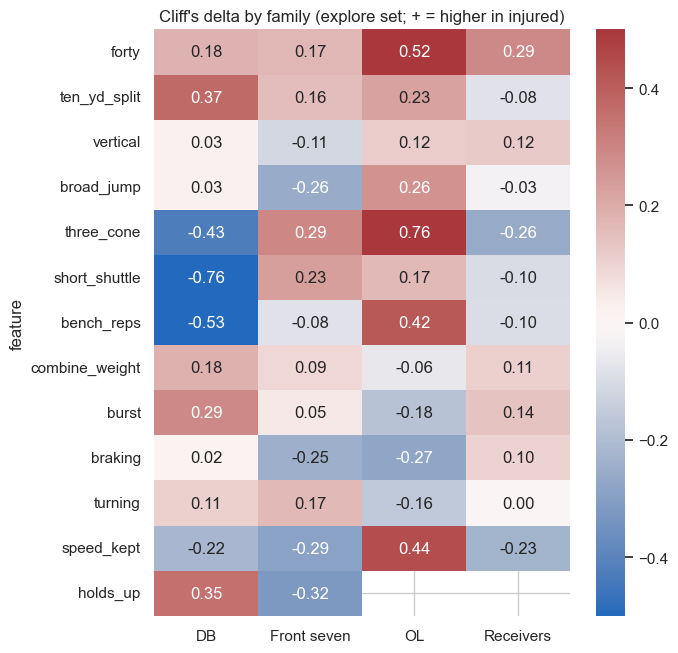

In [6]:
def cliffs_delta(a, b):
    a, b = np.asarray(a, float), np.asarray(b, float)
    return (np.sign(a[:, None] - b[None, :])).mean() if len(a) and len(b) else np.nan


def mwu(a, b):
    return stats.mannwhitneyu(a, b).pvalue if len(a) > 1 and len(b) > 1 else np.nan


def univariate(df, feats):
    rows = []
    for f in feats:
        a = df.loc[df.rookie_injured, f].dropna(); b = df.loc[~df.rookie_injured, f].dropna()
        rows.append(dict(feature=f, kind="tracked" if f in TRACK_COLS else "timed", n_injured=len(a), n_healthy=len(b),
                         cliffs_delta=cliffs_delta(a, b), p_value=mwu(a, b)))
    return pd.DataFrame(rows)


uni = univariate(EXP, FEATS).sort_values("cliffs_delta", key=abs, ascending=False)
display(uni.round(3))

by_fam = pd.DataFrame({fam: univariate(g, FEATS).set_index("feature").cliffs_delta
                       for fam, g in EXP.groupby("family")})
by_fam["n_injured"] = [EXP[f].notna().groupby(EXP.rookie_injured).sum().get(True, 0) for f in by_fam.index]
plt.figure(figsize=(7, 0.4 * len(FEATS) + 1.5))
sns.heatmap(by_fam.drop(columns="n_injured"), annot=True, fmt=".2f", cmap="vlag", center=0, vmin=-0.5, vmax=0.5)
plt.title("Cliff's delta by family (explore set; + = higher in injured)"); plt.tight_layout(); plt.show()

### 3b. Does tracked movement add to timed results? (cross-validated)
Three logistic models with the same folds: **base** (position family + draft round), **+ timed**, **+ timed + tracked**. AUC is averaged over 5-fold cross-validation repeated 20 times; the paired difference shows whether tracked movement adds anything beyond the timed results. One comparison, so no best-of-many problem.

In [7]:
def model_matrix(df, cols):
    X = pd.get_dummies(df.family, prefix="fam", drop_first=True).astype(float)
    X["draft_round"] = df.draft_round.values
    X["usage"] = df.usage.values
    for c in cols:
        X[c] = df[c].values
    return X


def make_model():
    return make_pipeline(SimpleImputer(strategy="median", add_indicator=True), StandardScaler(),
                         LogisticRegression(C=0.5, max_iter=5000))


def cv_compare(df, sets, n_repeats=20, seed=0):
    y = df.rookie_injured.astype(int).to_numpy()
    cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=n_repeats, random_state=seed)
    scores = {k: [] for k in sets}
    for tr, te in cv.split(np.zeros(len(y)), y):
        for k, cols in sets.items():
            X = model_matrix(df, cols).to_numpy()
            m = make_model().fit(X[tr], y[tr])
            scores[k].append(roc_auc_score(y[te], m.predict_proba(X[te])[:, 1]))
    return pd.DataFrame(scores)


SETS = {"base": [], "timed": TIMED_COLS, "timed+tracked": TIMED_COLS + TRACK_COLS, "tracked": TRACK_COLS}
cvs = cv_compare(EXP, SETS)
summary_cv = cvs.agg(["mean", "std"]).T.round(3)
summary_cv["vs_timed"] = [(cvs[k] - cvs["timed"]).mean().round(3) for k in summary_cv.index]
summary_cv["share_of_folds_beating_timed"] = [((cvs[k] - cvs["timed"]) > 0).mean().round(2) for k in summary_cv.index]
display(summary_cv)

,mean,std,vs_timed,share_of_folds_beating_timed
base,0.585,0.098,0.023,0.59
timed,0.563,0.080,0.000,0.00
timed+tracked,0.560,0.082,-0.003,0.54
tracked,0.581,0.091,0.018,0.57


### 3c. Severity and the drills behind each composite
Spearman correlation of each feature with games missed (injured players and healthy players together), and for the tracked composites, which drills drive the injured/healthy difference. This is where a drill recommendation would come from.

In [8]:
sev = pd.DataFrame([dict(feature=f, rho=EXP[[f, "rookie_games_out"]].dropna().corr(method="spearman").iloc[0, 1],
                         n=EXP[f].notna().sum()) for f in FEATS]).sort_values("rho", key=abs, ascending=False)
display(sev.round(3))

drill_rows = []
fz = first.merge(P[["nfl_id", "rookie_injured", "draft_year", "family"]], on="nfl_id")
fz = fz[fz.draft_year.isin(EXPLORE_CLASSES)]
for (d, m), g in fz.melt(id_vars=["nfl_id", "drill_name", "rookie_injured"], value_vars=RAW_MEAS,
                         var_name="measure").groupby(["drill_name", "measure"]):
    a = g.loc[g.rookie_injured, "value"].dropna(); b = g.loc[~g.rookie_injured, "value"].dropna()
    if len(a) >= 8 and len(b) >= 8:
        drill_rows.append(dict(drill=d, measure=m, n_injured=len(a), n_healthy=len(b), cliffs_delta=cliffs_delta(a, b),
                               p_value=mwu(a, b)))
drill_tbl = pd.DataFrame(drill_rows).sort_values("cliffs_delta", key=abs, ascending=False)
print(f"{len(drill_tbl)} drill-measure pairs with 8+ players per group; expect ~{0.05 * len(drill_tbl):.0f} "
      "at p < 0.05 by chance")
display(drill_tbl.head(15).round(3))

,feature,rho,n
0,forty,0.195,206
11,speed_kept,-0.165,177
5,short_shuttle,-0.099,87
1,ten_yd_split,0.098,206
9,braking,-0.093,233
7,combine_weight,0.064,233
6,bench_reps,-0.056,97
4,three_cone,0.045,77
2,vertical,0.045,208
12,holds_up,-0.030,105


157 drill-measure pairs with 8+ players per group; expect ~8 at p < 0.05 by chance


,drill,measure,n_injured,n_healthy,cliffs_delta,p_value
138,SPEED_OUT_ROUTE_LEFT,time_1yd,9,30,-0.563,0.005
114,SCREEN_DRILL,time_1yd,9,72,-0.485,0.018
106,RUN_THE_HOOP_DRILL,first_step,9,58,-0.471,0.024
155,W_DRILL,retention,10,18,-0.467,0.047
56,LINE,max_turn,9,30,0.430,0.055
11,BODY_CONTROL_DRILL,time_1yd,11,58,-0.387,0.040
103,RUN_AND_CLUB_DRILL,max_decel,10,59,-0.334,0.095
62,OL_PULL_DRILL_DEEP_SHORT_PULL_LEFT,first_step,8,52,-0.327,0.142
13,BOX_DRILL,max_decel,17,68,-0.326,0.039
136,SPEED_OUT_ROUTE_LEFT,max_decel,9,30,-0.326,0.147


## 4. Confirmation tests (write these down before Section 5)

After reviewing Section 3, fill in `CONFIRM_TESTS` with **at most 3 tests**, copy them into the findings doc, then set `CONFIRM_UNLOCKED = True` in Section 0 and run Section 5. Each test is run exactly once on the 2025 class.

Test types:
- `{"kind": "feature", "feature": "braking", "direction": -1}`: injured 2025 rookies have lower (`-1`) or higher (`+1`) values; one-sided Mann-Whitney.
- `{"kind": "model", "add": ["braking", "holds_up"]}`: a model trained on the explore set with timed results + these tracked features beats timed results alone on the 2025 class (AUC difference, bootstrap 95% interval).

In [9]:
CONFIRM_TESTS = [
    {"kind": "feature", "feature": "forty", "direction": 1},
    {"kind": "feature", "feature": "speed_kept", "direction": -1, "families": ["DB", "Receivers", "Front seven"]},
    {"kind": "model", "add": ["forty", "speed_kept"], "baseline": []},
]
print("Confirmation tests:", CONFIRM_TESTS)

Confirmation tests: [{'kind': 'feature', 'feature': 'forty', 'direction': 1}, {'kind': 'feature', 'feature': 'speed_kept', 'direction': -1, 'families': ['DB', 'Receivers', 'Front seven']}, {'kind': 'model', 'add': ['forty', 'speed_kept'], 'baseline': []}]


## 5. Confirmation on the 2025 class

In [10]:
def confirm(tests, n_boot=2000, seed=0):
    if not CONFIRM_UNLOCKED:
        print("Locked. Write the tests in Section 4 and the findings doc, then set CONFIRM_UNLOCKED = True.")
        return None
    if not tests:
        print("No confirmation tests written.")
        return None
    CON = P[(P.draft_year == CONFIRM_CLASS) & (P.family != "Other") & (P.rookie_games_played >= MIN_ROOKIE_GAMES)]
    print(f"{CONFIRM_CLASS} class: {len(CON)} players, {CON.rookie_injured.sum()} injured")
    rng = np.random.default_rng(seed)
    rows = []
    for t in tests:
        if t["kind"] == "feature":
            C = CON[CON.family.isin(t["families"])] if "families" in t else CON
            a = C.loc[C.rookie_injured, t["feature"]].dropna()
            b = C.loc[~C.rookie_injured, t["feature"]].dropna()
            alt = "less" if t["direction"] < 0 else "greater"
            p = stats.mannwhitneyu(a, b, alternative=alt).pvalue if len(a) > 1 and len(b) > 1 else np.nan
            label = f"{t['feature']} {'lower' if t['direction'] < 0 else 'higher'} in injured"
            if "families" in t:
                label += f" ({', '.join(t['families'])})"
            rows.append(dict(test=label, n_injured=len(a), n_healthy=len(b), effect=cliffs_delta(a, b),
                             effect_type="Cliff's delta", interval=None, p_value=p))
        else:
            base_cols = t.get("baseline", TIMED_COLS)
            y_tr = EXP.rookie_injured.astype(int)
            y_te = CON.rookie_injured.astype(int).to_numpy()
            preds = {}
            for name, cols in [("baseline", base_cols), ("baseline+add", base_cols + t["add"])]:
                X_tr = model_matrix(EXP, cols)
                m = make_model().fit(X_tr.to_numpy(), y_tr)
                X_te = model_matrix(CON, cols).reindex(columns=X_tr.columns, fill_value=0)
                preds[name] = m.predict_proba(X_te.to_numpy())[:, 1]
            diff = roc_auc_score(y_te, preds["baseline+add"]) - roc_auc_score(y_te, preds["baseline"])
            boots = []
            for _ in range(n_boot):
                i = rng.integers(0, len(y_te), len(y_te))
                if y_te[i].min() == y_te[i].max():
                    continue
                boots.append(roc_auc_score(y_te[i], preds["baseline+add"][i])
                             - roc_auc_score(y_te[i], preds["baseline"][i]))
            lo, hi = np.percentile(boots, [2.5, 97.5])
            rows.append(dict(test=f"baseline + {t['add']} beats baseline (AUC)", n_injured=int(y_te.sum()),
                             n_healthy=int(len(y_te) - y_te.sum()), effect=diff, effect_type="AUC difference",
                             interval=f"[{lo:.3f}, {hi:.3f}]", p_value=np.mean(np.array(boots) <= 0)))
    res = pd.DataFrame(rows)
    res.to_csv(OUT_DIR / "confirmation_results.csv", index=False)
    return res


confirm(CONFIRM_TESTS)

2025 class: 120 players, 32 injured


,test,n_injured,n_healthy,effect,effect_type,interval,p_value
0,forty higher in injured,24,70,0.132143,Cliff's delta,None,0.168966
1,"speed_kept lower in injured (DB, Receivers, Fr...",22,64,-0.156250,Cliff's delta,None,0.139230
2,"baseline + ['forty', 'speed_kept'] beats basel...",32,88,0.049006,AUC difference,"[-0.048, 0.149]",0.171000


In [12]:
w = z.pivot_table(index=["nfl_id", "drill_name"], columns="attempt", values="retention").dropna()
print("pairs with speed kept in both attempts:", len(w))
if len(w) >= 8:
    r = w[1].corr(w[2], method="spearman")
    print(f"attempt 1 vs 2: r = {r:.2f}, attempts for reliability 0.8 = {0.8 * (1 - r) / (r * 0.2):.1f}" if r > 0 else f"r = {r:.2f}")

pairs with speed kept in both attempts: 11
attempt 1 vs 2: r = 0.12, attempts for reliability 0.8 = 29.8
